# Week 3: Advanced Data Analysis and Visualization in Logistics
**Yuva Intern – Logistics Data Analyst Project**

This notebook explores the 600-row synthetic logistics dataset continued from Weeks 1 and 2. It calculates descriptive statistics and logistics KPIs, examines relationships among variables, and creates visualizations using Pandas, Matplotlib and Seaborn.

**Important:** The dataset is simulated for learning and is not actual company data.

## 1. Load libraries and dataset
Run in Google Colab. Upload `logistics_shipments_synthetic.csv` when prompted.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [2]:
file_path = "logistics_shipments_synthetic.csv"
if not os.path.exists(file_path):
    try:
        from google.colab import files
        uploaded = files.upload()
        file_path = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError("Place logistics_shipments_synthetic.csv in the notebook folder.")
df = pd.read_csv(file_path)
print("Dataset shape:", df.shape)
display(df.head())

Saving logistics_shipments.csv to logistics_shipments.csv
Dataset shape: (600, 14)


,order_id,shipment_id,order_date,warehouse,region,carrier,service_type,planned_distance_km,shipment_weight_kg,dispatch_time,promised_delivery_time,delivered_time,status,actual_cost_inr
0,ORD-0000,SHP-0000,2026-07-08,WH-02,West,Carrier A,Express,127.3,5.1,2026-07-08 10:00:00,2026-07-08 13:08:07.574840772,2026-07-08 13:08:07.574840772,Delivered,240.83
1,ORD-0001,SHP-0001,2026-08-24,WH-03,East,Carrier A,Express,170.0,8.9,2026-08-24 09:00:00,2026-08-24 12:53:23.199370789,NaN,Failed Attempt,368.73
2,ORD-0002,SHP-0002,2026-09-08,WH-03,South,Carrier A,Standard,112.6,12.3,2026-09-08 06:00:00,2026-09-08 07:39:20.290695955,2026-09-08 07:56:52.106701124,Delivered,224.95
3,ORD-0003,SHP-0003,2026-07-25,WH-01,North,Carrier C,Express,101.4,7.5,2026-07-25 17:00:00,2026-07-25 23:07:39.854973989,2026-07-25 21:32:20.633314066,Delivered,187.73
4,ORD-0004,SHP-0004,2026-07-22,WH-02,South,Carrier B,Standard,183.9,6.2,2026-07-22 02:00:00,2026-07-22 07:03:28.988774820,2026-07-22 06:23:53.903282452,Delivered,325.81


## 2. Prepare data and create analytical metrics

In [3]:
data = df.copy()
for col in ["order_date", "dispatch_time", "promised_delivery_time", "delivered_time"]:
    data[col] = pd.to_datetime(data[col], errors="coerce")
data["delivery_hours"] = (data["delivered_time"] - data["dispatch_time"]).dt.total_seconds()/3600
data["delay_hours"] = (data["delivered_time"] - data["promised_delivery_time"]).dt.total_seconds()/3600
data["is_delivered"] = data["status"].eq("Delivered")
data["on_time"] = data["is_delivered"] & data["delay_hours"].le(0)
data["month"] = data["order_date"].dt.to_period("M").astype(str)
delivered = data[data["is_delivered"] & data["delivery_hours"].notna()].copy()
display(data[["shipment_id","status","delivery_hours","delay_hours","on_time"]].head())

,shipment_id,status,delivery_hours,delay_hours,on_time
0,SHP-0000,Delivered,3.135437,0.000000,True
1,SHP-0001,Failed Attempt,NaN,NaN,False
2,SHP-0002,Delivered,1.947807,0.292171,False
3,SHP-0003,Delivered,4.539065,-1.588673,True
4,SHP-0004,Delivered,4.398306,-0.659746,True


## 3. Exploratory data analysis

In [4]:
print("Dataset dimensions:", data.shape)
print("\\nMissing values:")
display(data.isna().sum().to_frame("missing_count"))
print("\\nDescriptive statistics:")
display(data[["planned_distance_km","shipment_weight_kg","actual_cost_inr","delivery_hours","delay_hours"]].describe().T)

Dataset dimensions: (600, 19)
\nMissing values:


,missing_count
order_id,0
shipment_id,0
order_date,0
warehouse,0
region,0
carrier,5
service_type,0
planned_distance_km,0
shipment_weight_kg,8
dispatch_time,0


\nDescriptive statistics:


,count,mean,std,min,25%,50%,75%,max
planned_distance_km,600.0,118.951333,78.322189,7.400000,62.200000,103.500000,157.975000,450.000000
shipment_weight_kg,592.0,16.122466,11.880090,0.500000,7.700000,13.850000,21.225000,70.000000
actual_cost_inr,600.0,258.792233,117.225892,68.530000,178.035000,236.015000,312.530000,862.160000
delivery_hours,543.0,4.624414,2.239036,1.000000,3.093638,4.153346,6.024659,13.508811
delay_hours,543.0,-0.466578,0.960209,-3.516621,-1.071420,-0.348739,0.000000,2.026322


## 4. Logistics performance indicators

In [5]:
kpis = pd.DataFrame({
 "Metric": ["Total shipments","Delivered shipments","Delivery completion rate (%)",
            "Average delivery time (hours)","Median delivery time (hours)",
            "On-time delivery rate among delivered (%)","Average transportation cost (INR)"],
 "Value": [len(data),len(delivered),data["is_delivered"].mean()*100,
           delivered["delivery_hours"].mean(),delivered["delivery_hours"].median(),
           delivered["on_time"].mean()*100,data["actual_cost_inr"].mean()]
})
display(kpis.round(2))

,Metric,Value
0,Total shipments,600.00
1,Delivered shipments,543.00
2,Delivery completion rate (%),90.50
3,Average delivery time (hours),4.62
4,Median delivery time (hours),4.15
5,On-time delivery rate among delivered (%),76.80
6,Average transportation cost (INR),258.79


## 5. Visualizations and why they are used
1. **Bar/count chart:** compares categorical shipment outcomes.
2. **Line chart:** shows monthly shipment-volume trends over time.
3. **Histogram:** shows the distribution and spread of delivery duration.
4. **Bar chart:** compares average delivery time across carriers.
5. **Scatter plot:** examines the relationship between distance and cost.
6. **Correlation heatmap:** summarizes linear associations among numeric variables.

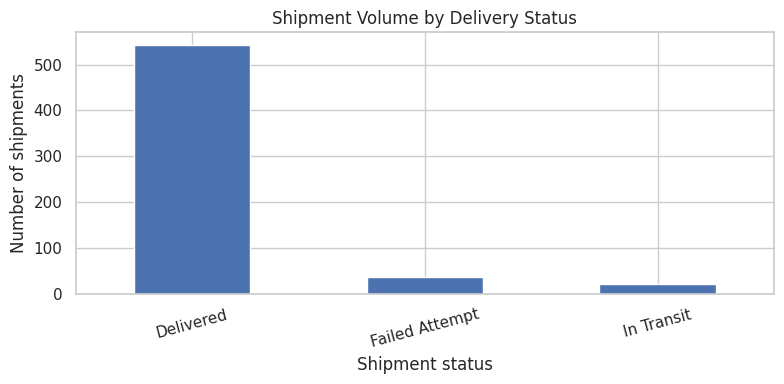

In [6]:
# 5.1 Shipment volume by status
data["status"].value_counts().plot(kind="bar", figsize=(8,4), title="Shipment Volume by Delivery Status")
plt.xlabel("Shipment status"); plt.ylabel("Number of shipments"); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

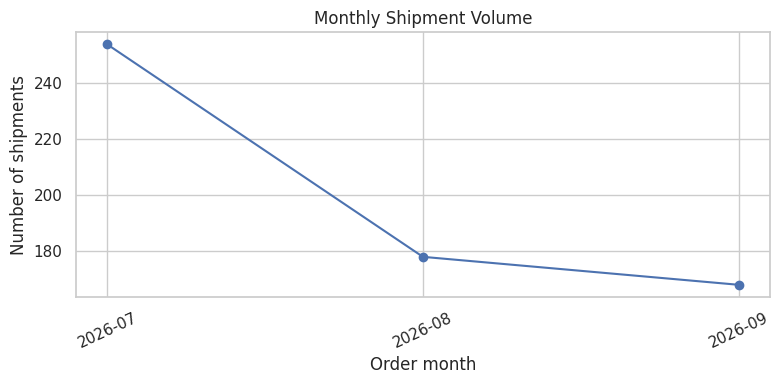

In [7]:
# 5.2 Monthly shipment volume
monthly_volume = data.groupby("month").size().reset_index(name="shipments")
plt.figure(figsize=(8,4)); plt.plot(monthly_volume["month"],monthly_volume["shipments"],marker="o")
plt.title("Monthly Shipment Volume"); plt.xlabel("Order month"); plt.ylabel("Number of shipments")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()

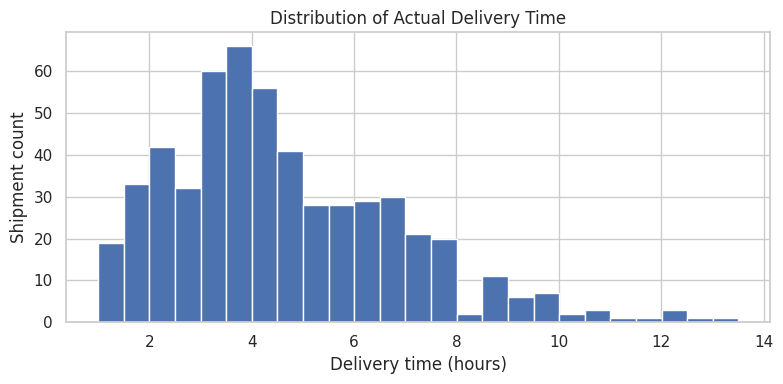

In [8]:
# 5.3 Delivery-time distribution (delivered shipments only)
plt.figure(figsize=(8,4)); plt.hist(delivered["delivery_hours"].dropna(),bins=25)
plt.title("Distribution of Actual Delivery Time"); plt.xlabel("Delivery time (hours)"); plt.ylabel("Shipment count")
plt.tight_layout(); plt.show()

,carrier,shipments,avg_delivery_hours,on_time_rate
0,Carrier A,174,4.84,0.76
1,Carrier B,183,4.55,0.80
2,Carrier C,182,4.51,0.74


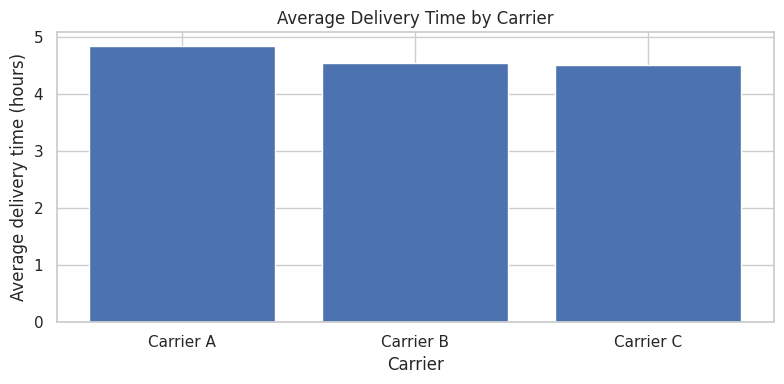

In [9]:
# 5.4 Carrier performance (delivered shipments only)
carrier_performance = delivered.groupby("carrier").agg(
    shipments=("shipment_id","count"),
    avg_delivery_hours=("delivery_hours","mean"),
    on_time_rate=("on_time","mean")
).reset_index()
display(carrier_performance.round(2))
plt.figure(figsize=(8,4)); plt.bar(carrier_performance["carrier"],carrier_performance["avg_delivery_hours"])
plt.title("Average Delivery Time by Carrier"); plt.xlabel("Carrier"); plt.ylabel("Average delivery time (hours)")
plt.tight_layout(); plt.show()

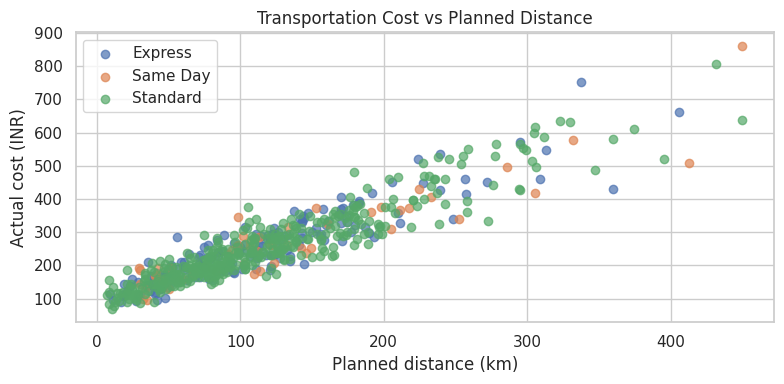

In [10]:
# 5.5 Transportation cost vs planned distance
plt.figure(figsize=(8,4))
for service, group in data.groupby("service_type"):
    plt.scatter(group["planned_distance_km"],group["actual_cost_inr"],label=service,alpha=0.7)
plt.title("Transportation Cost vs Planned Distance"); plt.xlabel("Planned distance (km)"); plt.ylabel("Actual cost (INR)")
plt.legend(); plt.tight_layout(); plt.show()

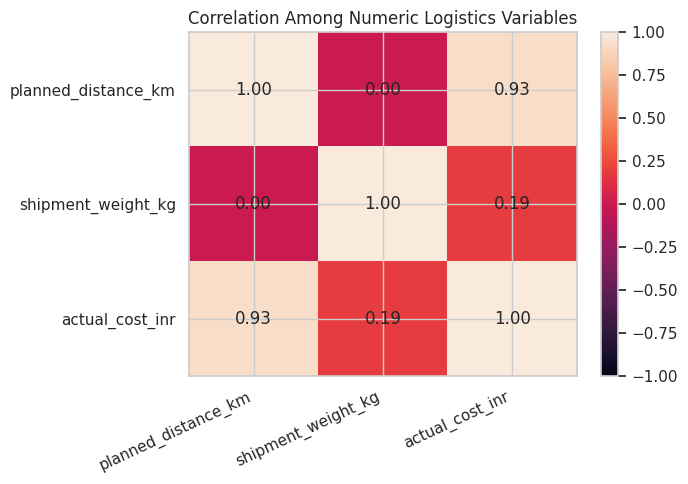

,planned_distance_km,shipment_weight_kg,actual_cost_inr
planned_distance_km,1.00,0.00,0.93
shipment_weight_kg,0.00,1.00,0.19
actual_cost_inr,0.93,0.19,1.00


In [11]:
# 5.6 Correlation heatmap
numeric_cols = ["planned_distance_km","shipment_weight_kg","actual_cost_inr"]
correlation = data[numeric_cols].corr()
plt.figure(figsize=(7,5)); plt.imshow(correlation,aspect="auto",vmin=-1,vmax=1); plt.colorbar()
plt.xticks(range(len(correlation.columns)),correlation.columns,rotation=25,ha="right")
plt.yticks(range(len(correlation.index)),correlation.index)
for i in range(len(correlation.index)):
    for j in range(len(correlation.columns)):
        plt.text(j,i,f"{correlation.iloc[i,j]:.2f}",ha="center",va="center")
plt.title("Correlation Among Numeric Logistics Variables"); plt.tight_layout(); plt.show()
display(correlation.round(2))

## 6. Group-wise analysis

In [12]:
region_summary = data.groupby("region").agg(
    shipments=("shipment_id","count"),
    avg_cost_inr=("actual_cost_inr","mean"),
    avg_distance_km=("planned_distance_km","mean")
).sort_values("shipments",ascending=False)
service_summary = data.groupby("service_type").agg(
    shipments=("shipment_id","count"),
    avg_cost_inr=("actual_cost_inr","mean"),
    delivered_rate=("is_delivered","mean")
)
service_summary["delivered_rate"] *= 100
display(region_summary.round(2)); display(service_summary.round(2))

,shipments,avg_cost_inr,avg_distance_km
region,,,
South,135,280.58,133.41
Central,129,248.18,113.21
West,122,242.92,111.36
East,108,268.24,121.31
North,106,252.59,113.85


,shipments,avg_cost_inr,delivered_rate
service_type,,,
Express,174,253.12,91.38
Same Day,54,270.83,90.74
Standard,372,259.70,90.05


## 7. Interpretation and limitations

In [13]:
print(f"Total shipments: {len(data)}")
print(f"Delivered shipments: {len(delivered)} ({data['is_delivered'].mean()*100:.1f}%)")
print(f"Average delivery time: {delivered['delivery_hours'].mean():.2f} hours")
print(f"On-time delivery rate among delivered shipments: {delivered['on_time'].mean()*100:.1f}%")
print(f"Average transportation cost: INR {data['actual_cost_inr'].mean():.2f}")
print(f"Distance-cost correlation: {data['planned_distance_km'].corr(data['actual_cost_inr']):.2f}")
print("Correlation shows association, not causation. Findings are illustrative because the data is synthetic.")

Total shipments: 600
Delivered shipments: 543 (90.5%)
Average delivery time: 4.62 hours
On-time delivery rate among delivered shipments: 76.8%
Average transportation cost: INR 258.79
Distance-cost correlation: 0.93
Correlation shows association, not causation. Findings are illustrative because the data is synthetic.


## 8. Export supporting outputs

In [14]:
output_dir = "week3_outputs"
os.makedirs(output_dir,exist_ok=True)
data.to_csv(os.path.join(output_dir,"week3_logistics_analysis_dataset.csv"),index=False)
kpis.to_csv(os.path.join(output_dir,"week3_kpi_summary.csv"),index=False)
carrier_performance.to_csv(os.path.join(output_dir,"week3_carrier_performance.csv"),index=False)
region_summary.to_csv(os.path.join(output_dir,"week3_region_summary.csv"))
print("Saved:",os.listdir(output_dir))

Saved: ['week3_region_summary.csv', 'week3_logistics_analysis_dataset.csv', 'week3_kpi_summary.csv', 'week3_carrier_performance.csv']


## 9. Conclusion
The analysis provides a structured view of shipment outcomes, delivery-time variation, carrier performance, monthly workload and transportation cost patterns. Apply the same workflow to validated operational data before making real business decisions.